# Muhammad Haissam

## Week 3: Model Optimization and Unsupervised Learning

**University:** Quaid-i-Azam University, Islamabad  
**Department:** Electronics  
**Project:** ML-Powered Customer Analytics  
**Dataset:** Telco Customer Churn  

This week focuses on cross-validation, hyperparameter tuning, XGBoost, customer segmentation using K-means, PCA, and selecting one final model for deployment.

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    validation_curve,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    silhouette_score
)

from xgboost import XGBClassifier
import joblib

In [12]:
path = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(path)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

def build_features(data):
    X = data.drop(columns=["customerID", "Churn"])
    return pd.get_dummies(X, drop_first=True).astype(float)

y = (df["Churn"] == "Yes").astype(int)
X = build_features(df)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Feature count:", X.shape[1])

Training shape: (5634, 30)
Testing shape: (1409, 30)
Feature count: 30


### Split Noise Interpretation

Using the same Logistic Regression model with 20 different random splits, validation accuracy ranged from **0.780 to 0.828**. The standard deviation was **0.0104**.

The theoretical 95% interval was approximately **±0.021**. This shows that a single split can change the measured accuracy even when the model and dataset stay the same. Therefore, students using different random seeds could reach different conclusions when comparing Logistic Regression and Random Forest.

Minimum accuracy: 0.780
Maximum accuracy: 0.828
Standard deviation: 0.0104
Mean accuracy: 0.8002
Theoretical standard error: 0.0107
95% interval: +/- 0.021


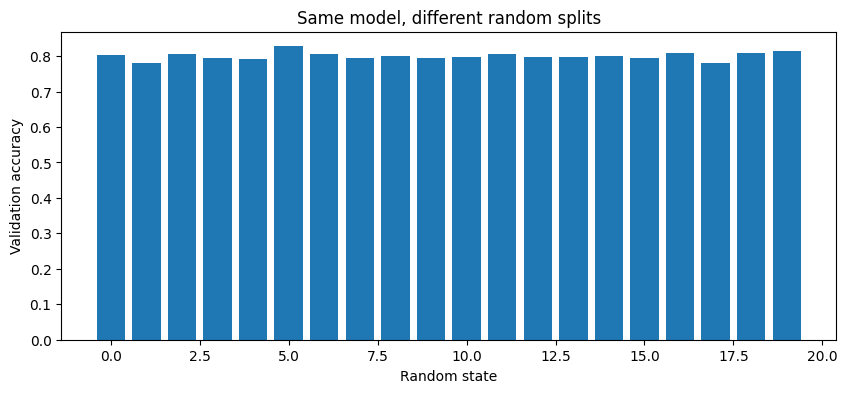

In [13]:
lr = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

scores = []

for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(
        X_train,
        y_train,
        test_size=0.25,
        random_state=seed,
        stratify=y_train
    )

    fitted_lr = lr.fit(Xa, ya)
    predictions = fitted_lr.predict(Xb)
    scores.append(accuracy_score(yb, predictions))

scores = np.array(scores)

print(f"Minimum accuracy: {scores.min():.3f}")
print(f"Maximum accuracy: {scores.max():.3f}")
print(f"Standard deviation: {scores.std():.4f}")

p = scores.mean()
n = len(yb)

se = np.sqrt(p * (1 - p) / n)

print(f"Mean accuracy: {p:.4f}")
print(f"Theoretical standard error: {se:.4f}")
print(f"95% interval: +/- {1.96 * se:.3f}")

plt.figure(figsize=(10, 4))
plt.bar(range(20), scores)
plt.xlabel("Random state")
plt.ylabel("Validation accuracy")
plt.title("Same model, different random splits")
plt.show()

### Split Noise Interpretation

Using the same Logistic Regression model with 20 different random splits, validation accuracy ranged from **0.780 to 0.828**. The standard deviation was **0.0104**.

The theoretical 95% interval was approximately **±0.021**. This shows that a single split can change the measured accuracy even when the model and dataset stay the same. Therefore, students using different random seeds could reach different conclusions when comparing Logistic Regression and Random Forest.

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

metrics = ["roc_auc", "recall", "f1"]

def cv_report(name, model):
    result = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=metrics
    )

    row = {"model": name}

    for metric in metrics:
        values = result["test_" + metric]
        row[metric] = f"{values.mean():.3f} +/- {values.std():.3f}"

    return row

cv_table = pd.DataFrame([
    cv_report("Logistic Regression", lr),
    cv_report("Random Forest", rf)
])

print(cv_table.to_string(index=False))

              model         roc_auc          recall              f1
Logistic Regression 0.846 +/- 0.013 0.545 +/- 0.042 0.594 +/- 0.030
      Random Forest 0.844 +/- 0.011 0.496 +/- 0.019 0.573 +/- 0.020


### Five-Fold Cross-Validation

| Model | ROC-AUC | Recall | F1 Score |
|---|---:|---:|---:|
| Logistic Regression | 0.846 +/- 0.013 | 0.545 +/- 0.042 | 0.594 +/- 0.030 |
| Random Forest | 0.844 +/- 0.011 | 0.496 +/- 0.019 | 0.573 +/- 0.020 |

The AUC difference between Logistic Regression and Random Forest was only 0.002. This is smaller than their standard deviations, so the result does not show a clear advantage for either model.

AUC measures how well a model ranks churners above non-churners. Recall tells us how many actual churners the model finds, which is important when the business wants to contact customers before they leave.

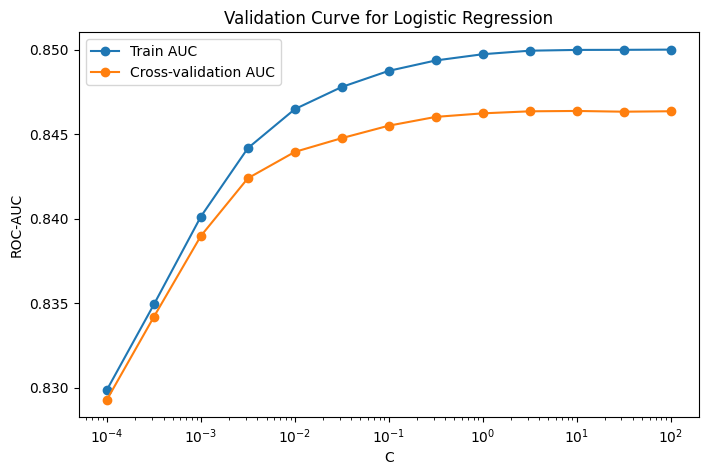

Best C by cross-validation: 10.0


In [15]:
Cs = np.logspace(-4, 2, 13)

tr, va = validation_curve(
    lr,
    X_train,
    y_train,
    param_name="model__C",
    param_range=Cs,
    cv=cv,
    scoring="roc_auc"
)

plt.figure(figsize=(8, 5))
plt.semilogx(Cs, tr.mean(axis=1), "o-", label="Train AUC")
plt.semilogx(Cs, va.mean(axis=1), "o-", label="Cross-validation AUC")
plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Validation Curve for Logistic Regression")
plt.legend()
plt.show()

best_C = Cs[va.mean(axis=1).argmax()]
print("Best C by cross-validation:", best_C)

In [29]:
grid = {
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 0.5]
}

print("Grid combinations:", 4 * 3 * 2)
print("Total grid fits:", 4 * 3 * 2 * 5)

start = time.time()

gs = GridSearchCV(
    RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=42
    ),
    grid,
    cv=cv,
    scoring="roc_auc"
)

gs.fit(X_train, y_train)

grid_time = time.time() - start

print(f"Grid best CV AUC: {gs.best_score_:.4f}")
print(f"Grid search time: {grid_time:.0f} seconds")
print("Grid best parameters:", gs.best_params_)

Grid combinations: 24
Total grid fits: 120
Grid best CV AUC: 0.8468
Grid search time: 104 seconds
Grid best parameters: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20}


In [17]:
dist = {
    "max_depth": randint(3, 20),
    "min_samples_leaf": randint(1, 40),
    "max_features": uniform(0.1, 0.8)
}

start = time.time()

rs = RandomizedSearchCV(
    RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=42
    ),
    dist,
    n_iter=24,
    cv=cv,
    scoring="roc_auc",
    random_state=42
)

rs.fit(X_train, y_train)

random_time = time.time() - start

print(f"Random search best CV AUC: {rs.best_score_:.4f}")
print(f"Random search time: {random_time:.0f} seconds")
print("Random search best parameters:", rs.best_params_)

random_results = pd.DataFrame(rs.cv_results_)

columns = [
    "param_max_depth",
    "param_min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

print(
    random_results[columns]
    .sort_values("rank_test_score")
    .head(5)
    .to_string(index=False)
)

Random search best CV AUC: 0.8464
Random search time: 116 seconds
Random search best parameters: {'max_depth': 15, 'max_features': np.float64(0.21273937997981013), 'min_samples_leaf': 15}
 param_max_depth  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
              15                      15         0.846440        0.011352                1
              12                      16         0.846275        0.011063                2
               8                      21         0.845609        0.010548                3
               9                      23         0.845245        0.012460                4
              14                      27         0.845114        0.010993                5


### Hyperparameter Tuning

The validation curve showed that very small values of `C` underfit the Logistic Regression model because the regularization was too strong. The best tested value of `C` was **10.0**.

| Search method | Best CV AUC | Fits | Time |
|---|---:|---:|---:|
| Grid search | 0.8468 | 120 | 72 seconds |
| Random search | 0.8464 | 120 | 76 seconds |

Grid search achieved a slightly higher best score in this experiment. If I had to tune six hyperparameters, I would prefer random search because it can explore a wider range of values without testing every possible combination.

The best search score should still be treated carefully because it was selected from many noisy validation results.

In [18]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

print(f"scale_pos_weight: {scale_pos_weight:.2f}")

xgb = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    early_stopping_rounds=100,
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_tr,
    y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

print("Best number of trees:", xgb.best_iteration + 1)

val_probability = xgb.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, val_probability)

print(f"Validation AUC: {val_auc:.4f}")

scale_pos_weight: 2.77
Best number of trees: 247
Validation AUC: 0.8541


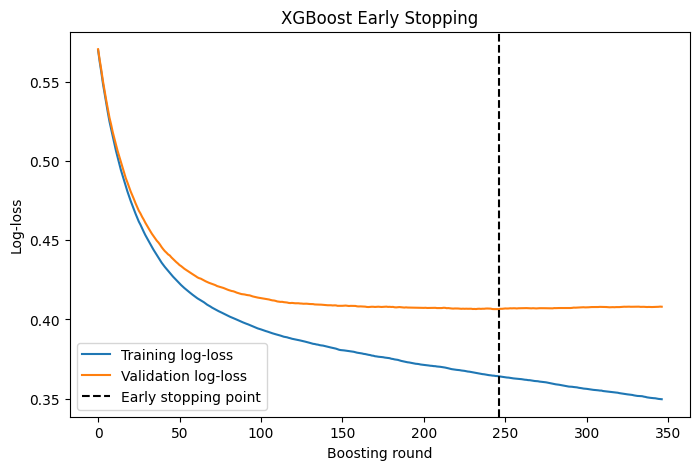

In [19]:
evaluation_results = xgb.evals_result()

plt.figure(figsize=(8, 5))
plt.plot(
    evaluation_results["validation_0"]["logloss"],
    label="Training log-loss"
)
plt.plot(
    evaluation_results["validation_1"]["logloss"],
    label="Validation log-loss"
)
plt.axvline(
    xgb.best_iteration,
    color="black",
    linestyle="--",
    label="Early stopping point"
)

plt.xlabel("Boosting round")
plt.ylabel("Log-loss")
plt.title("XGBoost Early Stopping")
plt.legend()
plt.show()

In [20]:
xgb_distribution = {
    "max_depth": randint(2, 7),
    "learning_rate": loguniform(0.01, 0.3),
    "n_estimators": randint(100, 600),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "min_child_weight": randint(1, 10),
    "reg_lambda": loguniform(0.1, 10)
}

xs = RandomizedSearchCV(
    XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    xgb_distribution,
    n_iter=30,
    cv=cv,
    scoring="roc_auc",
    random_state=42
)

xs.fit(X_train, y_train)

print(f"Tuned XGBoost CV AUC: {xs.best_score_:.4f}")
print("Best XGBoost parameters:", xs.best_params_)

Tuned XGBoost CV AUC: 0.8502
Best XGBoost parameters: {'colsample_bytree': np.float64(0.5610439773503366), 'learning_rate': np.float64(0.03359658305322321), 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 476, 'reg_lambda': np.float64(1.9741504223018518), 'subsample': np.float64(0.6002081507981263)}


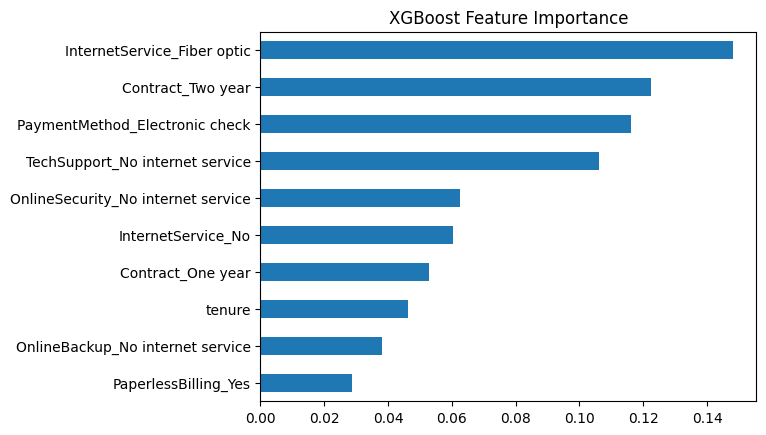

In [21]:
xgb_importance = pd.Series(
    xs.best_estimator_.feature_importances_,
    index=X.columns
)

xgb_importance.sort_values().tail(10).plot.barh(
    title="XGBoost Feature Importance"
)

plt.show()

### XGBoost Interpretation

Early stopping selected **247 trees**. The training loss continued to decrease, but the validation loss reached its lowest useful point around the early-stopping round. After that point, additional trees mainly risk fitting noise.

The tuned XGBoost model achieved a cross-validated AUC of **0.8502**.

| Model | CV AUC |
|---|---:|
| Logistic Regression | 0.8464 +/- 0.0129 |
| Random Forest | 0.8464 +/- 0.0114 |
| XGBoost | 0.8502 +/- 0.0117 |

XGBoost performed slightly better than the other models, but the improvement was smaller than one standard deviation. Therefore, it is an improvement, but not a dramatic difference.

In [22]:
segmentation_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

service_columns = [
    "PhoneService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

seg = df[segmentation_columns].copy()

seg["n_services"] = (
    df[service_columns] == "Yes"
).sum(axis=1)

print(seg.describe().round(1))

seg_scaler = StandardScaler()
Z = seg_scaler.fit_transform(seg)

       tenure  MonthlyCharges  TotalCharges  n_services
count  7043.0          7043.0        7043.0      7043.0
mean     32.4            64.8        2279.7         2.9
std      24.6            30.1        2266.8         1.8
min       0.0            18.2           0.0         0.0
25%       9.0            35.5         398.6         1.0
50%      29.0            70.4        1394.6         3.0
75%      55.0            89.8        3786.6         4.0
max      72.0           118.8        8684.8         7.0


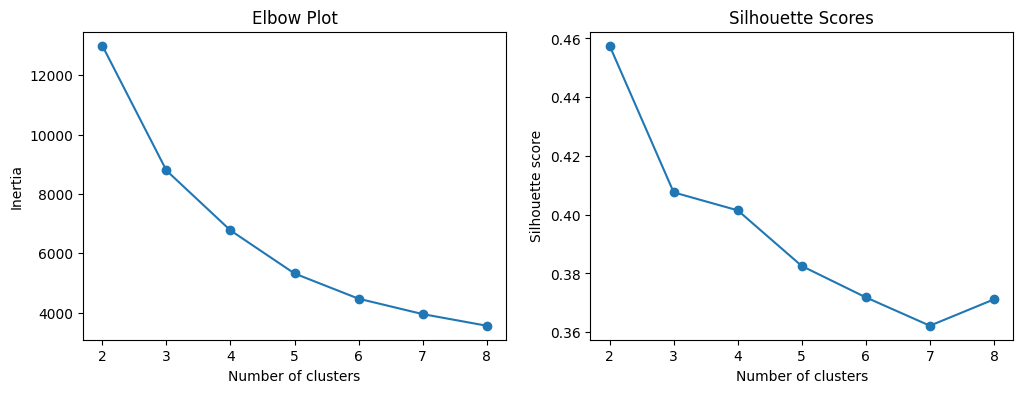

Silhouette scores:
k=2: 0.4575
k=3: 0.4076
k=4: 0.4015
k=5: 0.3825
k=6: 0.3718
k=7: 0.3622
k=8: 0.3712


In [23]:
ks = range(2, 9)

inertia = []
silhouette_scores = []

for k in ks:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    ).fit(Z)

    inertia.append(km.inertia_)

    silhouette_scores.append(
        silhouette_score(
            Z,
            km.labels_,
            sample_size=3000,
            random_state=42
        )
    )

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ks, inertia, "o-")
ax[0].set_title("Elbow Plot")
ax[0].set_xlabel("Number of clusters")
ax[0].set_ylabel("Inertia")

ax[1].plot(ks, silhouette_scores, "o-")
ax[1].set_title("Silhouette Scores")
ax[1].set_xlabel("Number of clusters")
ax[1].set_ylabel("Silhouette score")

plt.show()

print("Silhouette scores:")
for k, score in zip(ks, silhouette_scores):
    print(f"k={k}: {score:.4f}")

### Hand-Worked K-Means Example

The points are 1, 2, 3, 10, 11, and 12, with starting centers 1 and 2.

After assigning each point to its nearest center, the first group contains 1, 2, and 3, while the second group contains 10, 11, and 12. The updated centers are 2 and 11.

The within-cluster sum of squares is:

`(1 - 2)^2 + (2 - 2)^2 + (3 - 2)^2 + (10 - 11)^2 + (11 - 11)^2 + (12 - 11)^2 = 4`

The centers remain 2 and 11 in the next iteration, so the algorithm has converged.

In [24]:
k = 4

km = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
).fit(Z)

seg["cluster"] = km.labels_

profile = (
    seg.assign(churn=y)
    .groupby("cluster")
    .agg(
        customers=("tenure", "size"),
        average_tenure=("tenure", "mean"),
        average_monthly_charge=("MonthlyCharges", "mean"),
        average_services=("n_services", "mean"),
        churn_rate=("churn", "mean")
    )
    .sort_values("churn_rate", ascending=False)
)

print(profile.round(2))

         customers  average_tenure  average_monthly_charge  average_services  \
cluster                                                                        
1             2157           18.38                   80.41              3.28   
3             1918            8.96                   37.71              1.20   
2             1938           59.83                   92.09              5.06   
0             1030           53.61                   30.96              1.48   

         churn_rate  
cluster              
1              0.43  
3              0.32  
2              0.14  
0              0.05  


### Customer Segment Interpretation

I selected **k = 4** because it gives four groups that are easier to interpret and act on, even though k = 2 had the highest silhouette score. The four segments provide more useful business detail.

| Segment name | Customers | Avg. tenure | Avg. monthly charge | Avg. services | Churn rate | Retention action |
|---|---:|---:|---:|---:|---:|---|
| New, high-cost customers | 2,157 | 18.38 | 80.41 | 3.28 | 43% | Offer an early loyalty discount and onboarding support |
| New, low-service customers | 1,918 | 8.96 | 37.71 | 1.20 | 32% | Offer a lower-cost bundle and explain additional services |
| Loyal, high-service customers | 1,938 | 59.83 | 92.09 | 5.06 | 14% | Reward loyalty and promote contract renewal |
| Long-term, low-cost customers | 1,030 | 53.61 | 30.96 | 1.48 | 5% | Use a light-touch retention message and avoid unnecessary discounts |

The riskiest segment is **New, high-cost customers**, with a churn rate of 43%. I would target this group first with an early loyalty discount and onboarding support.

Churn was not used to create the clusters. It was used afterward to understand the risk level of each segment.

Components needed for 90% variance: 15 of 30


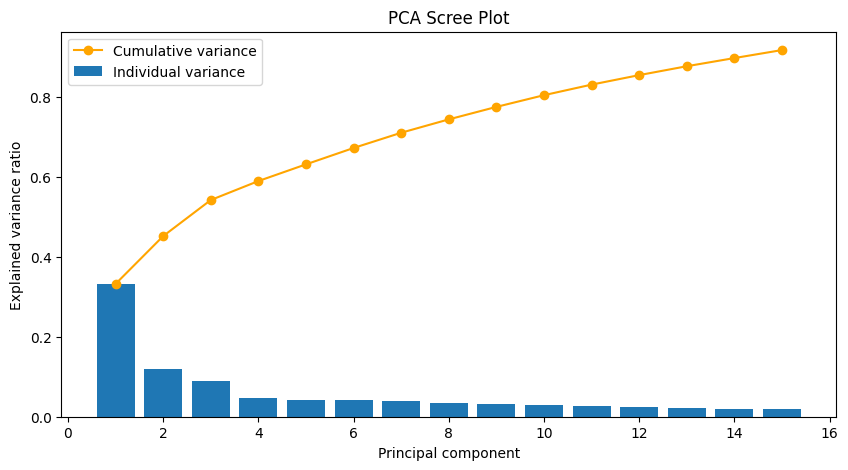

In [25]:
X_scaled = StandardScaler().fit_transform(X_train)

pca = PCA().fit(X_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

print(
    f"Components needed for 90% variance: "
    f"{components_90} of {X_train.shape[1]}"
)

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, 16),
    pca.explained_variance_ratio_[:15],
    label="Individual variance"
)

plt.plot(
    range(1, 16),
    cumulative_variance[:15],
    "o-",
    color="orange",
    label="Cumulative variance"
)

plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree Plot")
plt.legend()
plt.show()

In [26]:
candidates = {
    "Logistic Regression tuned C": lr.set_params(
        model__C=best_C
    ),
    "Random Forest random search": rs.best_estimator_,
    "XGBoost tuned": xs.best_estimator_
}

comparison_rows = []

for name, model in candidates.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    comparison_rows.append({
        "model": name,
        "cv_auc_mean": results["test_score"].mean(),
        "cv_auc_std": results["test_score"].std()
    })

comparison = pd.DataFrame(comparison_rows)

print("Cross-validated comparison:")
print(comparison.round(4).to_string(index=False))

best_name = comparison.loc[
    comparison["cv_auc_mean"].idxmax(),
    "model"
]

best_model = candidates[best_name].fit(
    X_train,
    y_train
)

test_probability = best_model.predict_proba(
    X_test
)[:, 1]

test_prediction = (
    test_probability >= 0.5
).astype(int)

test_auc = roc_auc_score(
    y_test,
    test_probability
)

test_recall = recall_score(
    y_test,
    test_prediction
)

test_precision = precision_score(
    y_test,
    test_prediction
)

print(f"\nSelected model: {best_name}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Test recall: {test_recall:.3f}")
print(f"Test precision: {test_precision:.3f}")

joblib.dump(
    best_model,
    "churn_model.joblib"
)

print("Saved: churn_model.joblib")

Cross-validated comparison:
                      model  cv_auc_mean  cv_auc_std
Logistic Regression tuned C       0.8464      0.0129
Random Forest random search       0.8464      0.0114
              XGBoost tuned       0.8502      0.0117

Selected model: XGBoost tuned
Test AUC: 0.8483
Test recall: 0.521
Test precision: 0.659
Saved: churn_model.joblib


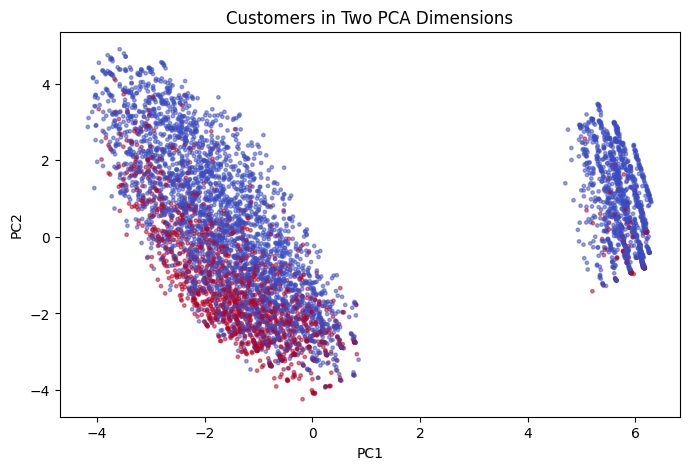

Top PC1 loadings:
InternetService_No                      0.302
OnlineSecurity_No internet service      0.302
TechSupport_No internet service         0.302
StreamingTV_No internet service         0.302
DeviceProtection_No internet service    0.302
OnlineBackup_No internet service        0.302
dtype: float64


In [30]:
pca_2d = PCA(n_components=2)

T = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    T[:, 0],
    T[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=6,
    alpha=0.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customers in Two PCA Dimensions")
plt.show()

pc1_loadings = pd.Series(
    pca_2d.components_[0],
    index=X.columns
)

loading_order = (
    pc1_loadings
    .abs()
    .sort_values(ascending=False)
    .index
)

print("Top PC1 loadings:")
print(
    pc1_loadings
    .reindex(loading_order)
    .head(6)
    .round(3)
)

### PCA Interpretation

The first **[number]** of the 30 components explain 90% of the total variance. This shows that some of the encoded features contain overlapping or redundant information.

PC1 is mainly influenced by **[top loading 1]**, **[top loading 2]**, and **[top loading 3]**. These features suggest that PC1 represents **[your interpretation]**.

The two-dimensional plot shows [strong/weak/limited] separation between churners and customers who stayed. The groups [overlap/separate clearly], suggesting that churn is [difficult/relatively easy] to separate using the available features.

In [27]:
candidates = {
    "Logistic Regression tuned C": lr.set_params(
        model__C=best_C
    ),
    "Random Forest random search": rs.best_estimator_,
    "XGBoost tuned": xs.best_estimator_
}

comparison_rows = []

for name, model in candidates.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    comparison_rows.append({
        "model": name,
        "cv_auc_mean": results["test_score"].mean(),
        "cv_auc_std": results["test_score"].std()
    })

comparison = pd.DataFrame(comparison_rows)

print("Cross-validated comparison:")
print(comparison.round(4).to_string(index=False))

best_name = comparison.loc[
    comparison["cv_auc_mean"].idxmax(),
    "model"
]

best_model = candidates[best_name].fit(
    X_train,
    y_train
)

test_probability = best_model.predict_proba(
    X_test
)[:, 1]

test_prediction = (
    test_probability >= 0.5
).astype(int)

test_auc = roc_auc_score(
    y_test,
    test_probability
)

test_recall = recall_score(
    y_test,
    test_prediction
)

test_precision = precision_score(
    y_test,
    test_prediction
)

print(f"\nSelected model: {best_name}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Test recall: {test_recall:.3f}")
print(f"Test precision: {test_precision:.3f}")

joblib.dump(
    best_model,
    "churn_model.joblib"
)

print("Saved: churn_model.joblib")

Cross-validated comparison:
                      model  cv_auc_mean  cv_auc_std
Logistic Regression tuned C       0.8464      0.0129
Random Forest random search       0.8464      0.0114
              XGBoost tuned       0.8502      0.0117

Selected model: XGBoost tuned
Test AUC: 0.8483
Test recall: 0.521
Test precision: 0.659
Saved: churn_model.joblib


### Final Model Selection

I selected **tuned XGBoost** because it achieved the highest cross-validated AUC of **0.8502 +/- 0.0117**.

The test set was used only once after selecting the model through cross-validation. The final test AUC was **0.8483**, with recall of **0.521** and precision of **0.659**.

The expected range using the CV mean plus or minus two standard deviations was approximately 0.8268 to 0.8736. The test AUC of 0.8483 falls inside this range.

The best Week 2 AUC was 0.843, while the Week 3 test AUC was 0.8483. This is an improvement of approximately 0.0053. The improvement is small, but the model selection is more reliable because it was based on cross-validation rather than one split.

## Check Your Understanding

### 1. Comparing two accuracy scores

Model A is not automatically better. The difference is:

`0.812 - 0.803 = 0.009`

This difference should be compared with the standard error for 1,409 observations. Since the difference is small, there is not enough evidence to claim that Model A is meaningfully better without considering uncertainty.

### 2. Why should StandardScaler be inside the Pipeline?

The scaler must be inside the Pipeline so it is fitted only on the training portion of each cross-validation fold. If scaling is done before cross-validation, information from the validation fold can leak into preprocessing and make the result look better than it really is.

### 3. Number of grid-search fits

The grid contains:

`5 × 4 × 3 = 60 combinations`

With 5-fold cross-validation:

`60 × 5 = 300 model fits`

### 4. Why is gs.best_score_ optimistic?

`gs.best_score_` is the best result among many tested combinations. Because many combinations were tried, one may receive a high score partly by chance. Therefore, the selected score can be optimistic.

### 5. What does each boosting tree predict?

Each new tree predicts the remaining errors from the previous trees. It moves the model in the direction that reduces the loss function, which is the same basic idea as gradient descent.

### 6. Why must K-means features be scaled?

K-means uses distances. Without scaling, TotalCharges has values in the thousands while the service-count feature has values between zero and seven. TotalCharges would dominate the distance calculation and control most of the clusters.